# Fase 2 · Líneas base

Pronóstico de los casos semanales de dengue por departamento con **1 a 4 semanas de anticipación**, usando solo información disponible en la semana *T − h*.

| Modelo | Idea |
|---|---|
| **Persistencia** | Repite los casos de *T − h* (referencia ingenua) |
| **Promedio estacional** | Media de los casos de la misma semana epidemiológica en los años anteriores |
| **Regresión con casos rezagados** | Regresión lineal de log1p(casos) sobre los casos de *T − h* a *T − h − 3*, una por departamento y horizonte |

**División temporal** (`scripts/comun.py`): se ajusta con 2010–2021 y se evalúa en validación (2022–2023); para la prueba se reajusta con 2010–2023 y se evalúa en 2024. Métricas en la escala de casos: RMSE, MAE y R².

Si el XGBoost con clima (notebook 09) no supera estas líneas base, el clima no está aportando.

**Entrada:** `data/processed/panel_depto_semana.parquet` (scripts 01 a 07).
**Salidas:** `outputs/fase2_lineas_base_metricas.csv`, `outputs/fase2_lineas_base_2024.png` y `data/processed/predicciones_lineas_base.parquet` (la usa el notebook 09).

## Configuración

In [1]:
# Rutas: el notebook funciona desde la raiz del proyecto o desde notebooks/
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))  # para importar scripts/comun.py

In [2]:
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from comun import (ENTRENAMIENTO, EXCLUIR_MODELO, HORIZONTES, MIN_CASOS_TRAIN, PRUEBA, REGIONES,
                   VALIDACION)

PROC = ROOT / "data" / "processed"
OUT = ROOT / "outputs"

N_REZAGOS = 4               # rezagos de casos del modelo 2: h .. h + 3
# (nombre, ultimo ano de ajuste, rango evaluado)
EVALUACIONES = [("Validacion", ENTRENAMIENTO[1], VALIDACION), ("Prueba", VALIDACION[1], PRUEBA)]

PERSISTENCIA, ESTACIONAL, REGRESION = "Persistencia", "Promedio estacional", "Regresion con rezagos"

panel = pd.read_parquet(PROC / "panel_depto_semana.parquet")
panel = panel.sort_values(["departamento", "ano", "semana"]).reset_index(drop=True)
g = panel.groupby("departamento", sort=False)

## Promedio estacional

In [3]:
def promedio_estacional(df: pd.DataFrame) -> np.ndarray:
    """Media de la misma semana en los anos anteriores, por departamento."""
    sem = df["semana"].clip(upper=52)  # la semana 53 usa la historia de la 52
    tabla = (df.assign(sem=sem).pivot_table(index=["departamento", "sem"], columns="ano",
                                           values="casos", aggfunc="sum"))
    # Media expansiva de los anos ESTRICTAMENTE anteriores
    previa = tabla.T.expanding().mean().shift(1).T
    largo = previa.stack().rename("estacional").reset_index()
    return df.assign(sem=sem).merge(largo, on=["departamento", "sem", "ano"], how="left")["estacional"].to_numpy()


panel["pred_estacional"] = promedio_estacional(panel)
panel["log_casos"] = np.log1p(panel["casos"])

## Ajuste y evaluación por departamento y horizonte

In [4]:
filas_metricas, predicciones = [], []
casos_train = panel[panel["ano"] <= ENTRENAMIENTO[1]].groupby("departamento")["casos"].sum()
deptos = [d for d in casos_train[casos_train >= MIN_CASOS_TRAIN].index if d not in EXCLUIR_MODELO]
print(f"Departamentos evaluados ({len(deptos)}): {', '.join(deptos)}")

for h in HORIZONTES:
    rezagos = [f"log_casos_l{h + k}" for k in range(N_REZAGOS)]
    for k in range(N_REZAGOS):
        panel[f"log_casos_l{h + k}"] = g["log_casos"].shift(h + k)
    panel[f"pred_persistencia_h{h}"] = g["casos"].shift(h)

    for depto in deptos:
        d = panel[panel["departamento"] == depto]
        for conjunto, ultimo_ajuste, (inicio, fin) in EVALUACIONES:
            ajuste = d[d["ano"] <= ultimo_ajuste].dropna(subset=rezagos)
            evaluado = d[d["ano"].between(inicio, fin)]
            assert evaluado[rezagos + ["pred_estacional"]].notna().all().all()

            modelo = LinearRegression().fit(ajuste[rezagos], ajuste["log_casos"])
            pred_reg = np.clip(np.expm1(modelo.predict(evaluado[rezagos])), 0, None)
            preds = {
                PERSISTENCIA: evaluado[f"pred_persistencia_h{h}"].to_numpy(),
                ESTACIONAL: evaluado["pred_estacional"].to_numpy(),
                REGRESION: pred_reg,
            }
            y = evaluado["casos"].to_numpy()
            for nombre, p in preds.items():
                filas_metricas.append({
                    "conjunto": conjunto, "departamento": depto, "horizonte": h, "modelo": nombre,
                    "rmse": float(np.sqrt(mean_squared_error(y, p))),
                    "mae": float(mean_absolute_error(y, p)),
                    "r2": float(r2_score(y, p)),
                    "casos_evaluados": int(y.sum()), "n_semanas_evaluadas": len(y),
                    "n_semanas_ajuste": len(ajuste),
                })
            predicciones.append(pd.DataFrame({
                "conjunto": conjunto, "departamento": depto, "ano": evaluado["ano"].to_numpy(),
                "semana": evaluado["semana"].to_numpy(), "fecha": evaluado["fecha"].to_numpy(),
                "horizonte": h, "casos": y, "pred_persistencia": preds[PERSISTENCIA],
                "pred_estacional": preds[ESTACIONAL], "pred_regresion": preds[REGRESION],
            }))

metricas = pd.DataFrame(filas_metricas)
metricas.to_csv(OUT / "fase2_lineas_base_metricas.csv", index=False, float_format="%.4f")
pred = pd.concat(predicciones, ignore_index=True)
pred.to_parquet(PROC / "predicciones_lineas_base.parquet", index=False)

Departamentos evaluados (17): AMAZONAS, ANCASH, AYACUCHO, CAJAMARCA, CUSCO, HUANUCO, ICA, JUNIN, LA LIBERTAD, LAMBAYEQUE, LORETO, MADRE DE DIOS, PASCO, PIURA, SAN MARTIN, TUMBES, UCAYALI


## Resumen de resultados

In [5]:
pd.set_option("display.width", 160)
foco = metricas[metricas["departamento"].isin(REGIONES)]
for conjunto, _, (inicio, fin) in EVALUACIONES:
    sub = foco[foco["conjunto"] == conjunto]
    print(f"\n{conjunto} {inicio}-{fin}, regiones principales, R2:")
    print(sub.pivot_table(index=["departamento", "modelo"], columns="horizonte", values="r2").round(3).to_string())
prueba = metricas[metricas["conjunto"] == "Prueba"]
mejor = (prueba.loc[prueba.groupby(["departamento", "horizonte"])["mae"].idxmin()]
         .groupby(["horizonte", "modelo"]).size().unstack(fill_value=0))
print("\nPrueba: modelo con menor MAE, numero de departamentos por horizonte:")
print(mejor.to_string())


Validacion 2022-2023, regiones principales, R2:
horizonte                               1      2      3      4
departamento modelo                                           
LORETO       Persistencia           0.816  0.658  0.472  0.223
             Promedio estacional   -0.299 -0.299 -0.299 -0.299
             Regresion con rezagos  0.812  0.647  0.463  0.266
PIURA        Persistencia           0.916  0.765  0.540  0.319
             Promedio estacional   -0.099 -0.099 -0.099 -0.099
             Regresion con rezagos  0.870  0.731  0.558  0.402
SAN MARTIN   Persistencia           0.788  0.659  0.449  0.302
             Promedio estacional   -1.996 -1.996 -1.996 -1.996
             Regresion con rezagos  0.704  0.465  0.182 -0.086

Prueba 2024-2024, regiones principales, R2:
horizonte                               1      2      3      4
departamento modelo                                           
LORETO       Persistencia           0.832  0.657  0.432  0.262
             Promedio es

## Gráfico: prueba 2024, regiones principales

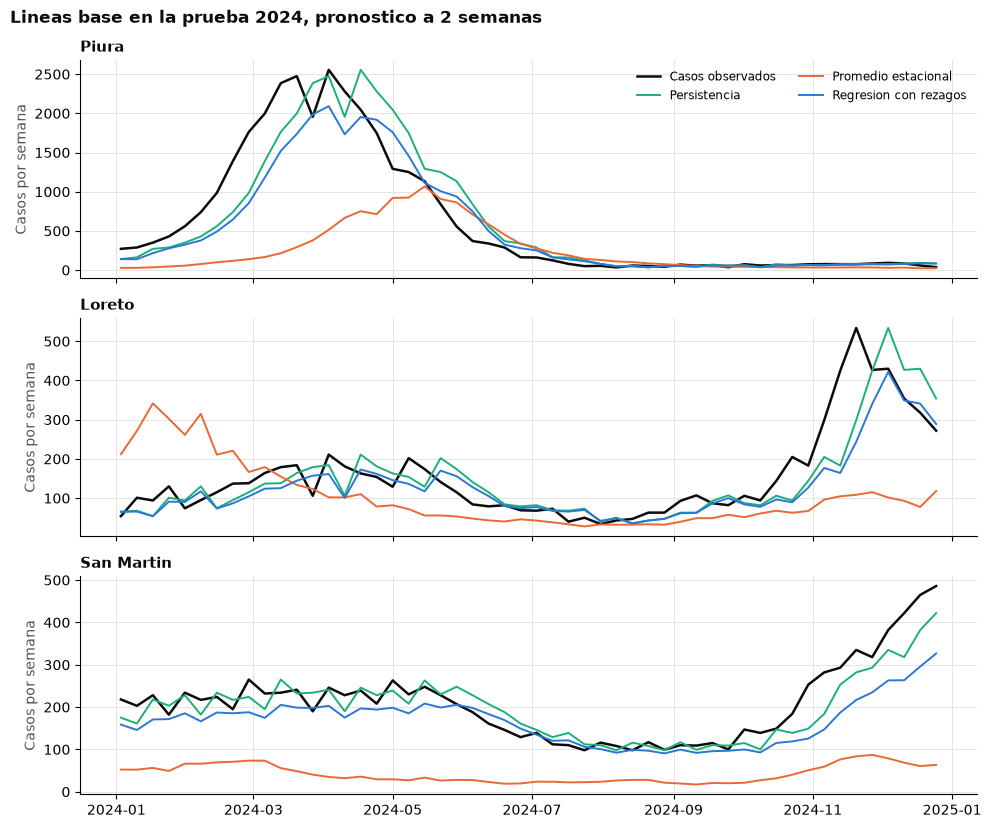


Guardado outputs/fase2_lineas_base_metricas.csv y outputs/fase2_lineas_base_2024.png


In [6]:
AZUL, NARANJA, AQUA, TINTA, TINTA_2, REJILLA = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#52514e", "#e1e0d9"
H_GRAFICO = 2
fig, ejes = plt.subplots(len(REGIONES), 1, figsize=(10, 2.8 * len(REGIONES)), sharex=True)
for ax, depto in zip(np.atleast_1d(ejes), REGIONES):
    p = pred[(pred["departamento"] == depto) & (pred["horizonte"] == H_GRAFICO) & (pred["conjunto"] == "Prueba")]
    ax.plot(p["fecha"], p["casos"], color=TINTA, lw=1.8, label="Casos observados")
    ax.plot(p["fecha"], p["pred_persistencia"], color=AQUA, lw=1.4, label="Persistencia")
    ax.plot(p["fecha"], p["pred_estacional"], color=NARANJA, lw=1.4, label="Promedio estacional")
    ax.plot(p["fecha"], p["pred_regresion"], color=AZUL, lw=1.4, label="Regresion con rezagos")
    ax.set_title(f"{depto.title()}", loc="left", fontsize=11, fontweight="bold", color=TINTA)
    ax.set_ylabel("Casos por semana", color=TINTA_2)
    ax.grid(color=REJILLA, lw=0.6)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
np.atleast_1d(ejes)[0].legend(loc="upper right", fontsize=8.5, frameon=False, ncol=2)
fig.suptitle(f"Lineas base en la prueba 2024, pronostico a {H_GRAFICO} semanas", x=0.01, ha="left",
             fontsize=12, fontweight="bold", color=TINTA)
fig.tight_layout()
fig.savefig(OUT / "fase2_lineas_base_2024.png", dpi=120)
plt.show()
print("\nGuardado outputs/fase2_lineas_base_metricas.csv y outputs/fase2_lineas_base_2024.png")

## Resultados y conclusiones

**R² en la prueba 2024** (pronóstico a 1 / 2 / 3 / 4 semanas):

| Región | Persistencia | Regresión con rezagos | Promedio estacional |
|---|---|---|---|
| Piura | 0,94 / 0,85 / 0,71 / 0,52 | 0,92 / 0,84 / **0,74** / **0,61** | 0,01 |
| Loreto | **0,83** / **0,66** / **0,43** / **0,26** | 0,82 / 0,63 / 0,41 / 0,22 | −0,63 |
| San Martín | **0,88** / **0,82** / **0,65** / **0,51** | 0,75 / 0,50 / 0,18 / −0,10 | −3,09 |

En validación (2022–2023) el patrón es el mismo: por ejemplo, en Piura la regresión pasa de 0,87 a 1 semana a 0,40 a 4 semanas.

**Conclusiones**

1. **A 1 semana casi todo lo explica la inercia de los casos.** La persistencia, que solo repite los casos de hace una semana, alcanza un R² de 0,83 a 0,94 en las tres regiones y tiene el menor error en 11 de los 17 departamentos.
2. **El desempeño cae rápido con la anticipación.** A 4 semanas el R² baja a 0,2–0,6. Ese es el margen que el clima tiene que mejorar en el notebook 09.
3. **La regresión con casos rezagados gana a más semanas de anticipación:** tiene el menor error en 14 de 17 departamentos a 4 semanas. Pero subestima los picos, porque se ajusta en escala logarítmica y pierde nivel al volver a casos; se ve en San Martín a fines de 2024.
4. **El promedio estacional falla en 2022–2024** (R² cercano a 0 o negativo), porque fueron años epidémicos atípicos. Mirar solo el calendario no basta.

**Estas son las referencias que debe superar el XGBoost del notebook 09.** Lima está fuera del modelo principal (ver `EXCLUIR_MODELO` en `scripts/comun.py`): sus casos son casi todos de 2023–2024.
